# Homework 2
Due Wednesday Oct 14, 11:59pm (EST)

Rachel Liu

Teammates: Constance Chen

### 1: Binary Classification on Text Data


In [70]:
import re                      # regular expressions, used by clean_text in part (c)
import numpy as np            
import pandas as pd        

import sklearn
from sklearn.model_selection import train_test_split         
from sklearn.feature_extraction.text import CountVectorizer  
from sklearn.linear_model import LogisticRegression          
from sklearn.metrics import f1_score                         

SEED = 99

### (a) Download the data

In [71]:
# Read the three files into pandas DataFrames
train_df = pd.read_csv("data/train.csv")             # id,model,task,text,behavior,target
test_df = pd.read_csv("data/test.csv")               # id,model,task,text
test_labels_df = pd.read_csv("data/test_labels.csv") # id,target 

# .shape gives (number of rows, number of columns)
print("train.csv shape:", train_df.shape)
print("test.csv  shape:", test_df.shape)
print("columns in train:", train_df.columns.tolist())

# Take a look at the first few rows.
train_df.head()

# Flagged training transcripts is where the target is 1
flagged_train_df = train_df[train_df['target'] == 1]
unflagged_train_df = train_df[train_df['target'] == 0]

print((len(flagged_train_df)/5026)*100, (1-len(flagged_train_df)/5026)*100)

train.csv shape: (5026, 6)
test.csv  shape: (2153, 4)
columns in train: ['id', 'model', 'task', 'text', 'behavior', 'target']
15.777954635893355 84.22204536410665


### (b) Split the training data
We fit models on the training set and use the held-out development (validation) set to compare models and pick hyperparameters. The test set is used only once.

In [72]:
# train_test_split randomly shuffles the rows and cuts them 70/30.
#   test_size=0.3       so 30% goes to the development set
#   random_state=SEED   so that it is the same split every time we run the notebook
train_set, dev_set = train_test_split(
    train_df, test_size=0.3, random_state=SEED
)

# y = the labels we are trying to predict, as numpy arrays of 0/1.
y_train = train_set["target"].values
y_dev = dev_set["target"].values

print("training set size:   ", len(train_set), f"({y_train.mean()*100:.2f}% flagged)")
print("development set size:", len(dev_set), f"({y_dev.mean()*100:.2f}% flagged)")

training set size:    3518 (15.12% flagged)
development set size: 1508 (17.31% flagged)


### (c) Preprocess the data
Based off the segment of flagged transcripts, I noticed that models tend to most demonstrate misbehavior through particular words, so I decided on each preprocessing step based on that.

| Step | Applied? |
|---|---|
| Convert all words to lowercase | Yes |
| Lemmatize all the words | No |
| Strip punctuation | Yes |
| Strip the stop words | No |
| Strip numbers, file paths, and long random-looking strings | Yes |
| Strip whitespace | Yes |

In [73]:
# Create a function that takes text and returns the preprocessed text using regex.

def clean_text(text):
    # Convert all the words to lowercase
    text = text.lower()

    # Strip numbers, file paths, and long random-looking strings.
    ##  Remove file paths which are "x/" chunks followed by a name,
    ##  e.g. "/this/is/file.py" or "this/also/file.py".
    text = re.sub(r"(?:[\w.~-]*/)+[\w.-]+", " ", text)
    ##  Remove long random-looking strings of 16+ characters.
    text = re.sub(r"\b[0-9a-fA-F]{16,}\b", " ", text)

    # Strip punctuation (not apostrophes so negations stay)
    text = re.sub(r"['’]", "", text)
    ##  Everything else that is not a letter/digit/whitespace becomes a space.
    ##  We also turn "_" into a space so snake_case identifiers split into words.
    text = re.sub(r"[^\w\s]|_", " ", text)

    # Remove any tokens that contain a digit
    ##  \S* = any non-space characters, \d = a digit.
    text = re.sub(r"\S*\d\S*", " ", text)

    # Strip whitespace
    return re.sub(r"\s+", " ", text).strip()

# Checking the clean_text function on an example string created by Claude.
example = "[bash] cat /home/agent/run_42.py  # Sabotage? I should NOT do this! I shouldn't. hash=a3f9c0e1b2d4f6a8c0e1"
print("before:", example)
print("after: ", clean_text(example))

before: [bash] cat /home/agent/run_42.py  # Sabotage? I should NOT do this! I shouldn't. hash=a3f9c0e1b2d4f6a8c0e1
after:  bash cat sabotage i should not do this i shouldnt hash


In [74]:
# Apply the cleaning function to every transcript. `.map` calls clean_text on each row.
train_text = train_set["text"].map(clean_text)
dev_text = dev_set["text"].map(clean_text)

# Show a cleaned snippet from a real transcript.
print(train_text.iloc[0][:400])

version ambiguity without confirmation of whether or is considered the definitive original ppo paper i cannot be certain which version to reference character encoding issues the pdf contains special typographic elements like the ﬁ ligature that create uncertainty in precise character position counting definition precision without clarification on whether letter refers specifically to alphabetic ch


### (d) Bag-of-words model

In [75]:
# Choose M by trying a range of thresholds M and recording vocabulary size.
for M in [1, 2, 5, 10, 20]:
    vec = CountVectorizer(binary=True, min_df=M)
    X_tr = vec.fit_transform(train_text)
    print(f"M = {M:3d}   #features = {X_tr.shape[1]:6d}")

M =   1   #features =  10495
M =   2   #features =   7183
M =   5   #features =   4868
M =  10   #features =   3705
M =  20   #features =   2711


In [76]:
M_BOW = 5   # My chosen threshold

# Fit vectorizer once, on the training set only.
bow_vectorizer = CountVectorizer(binary=True, min_df=M_BOW)
X_train_bow = bow_vectorizer.fit_transform(train_text)      # learn vocab + transform train
X_dev_bow = bow_vectorizer.transform(dev_text)              # transform dev with the same vocab

# These are sparse matrices (most entries are 0), which saves a lot of memory.
print("Threshold M =", M_BOW)
print("Total number of features:", X_train_bow.shape[1])
print("train matrix:", X_train_bow.shape, "   dev matrix:", X_dev_bow.shape)

Threshold M = 5
Total number of features: 4868
train matrix: (3518, 4868)    dev matrix: (1508, 4868)


### (e) Logistic regression
#### (e)(i) No regularization

In [77]:
def report(name, clf, X_tr, X_dv):
    """Print and return training F1 and development F1."""
    # f1_score is defined in sklearn and takes in true labels and 
    # predicted labels to compute the F1 score.
    f1_tr = f1_score(y_train, clf.predict(X_tr))
    f1_dv = f1_score(y_dev, clf.predict(X_dv))
    return f1_tr, f1_dv

In [78]:
# C=np.inf turns regularization off completely, model can make weights as large as it wants
# Did not get convergence warnings, so I did not raise max_iter.
lr_none = LogisticRegression(C=np.inf)
lr_none.fit(X_train_bow, y_train)
results = {}   # stores (training F1, dev F1) for every model, used in parts (f)-(i)
results["LR no regularization"] = report("LR, no regularization", lr_none, X_train_bow, X_dev_bow)
results["LR no regularization"]

(1.0, 0.860655737704918)

#### (e)(ii) L1 regularization

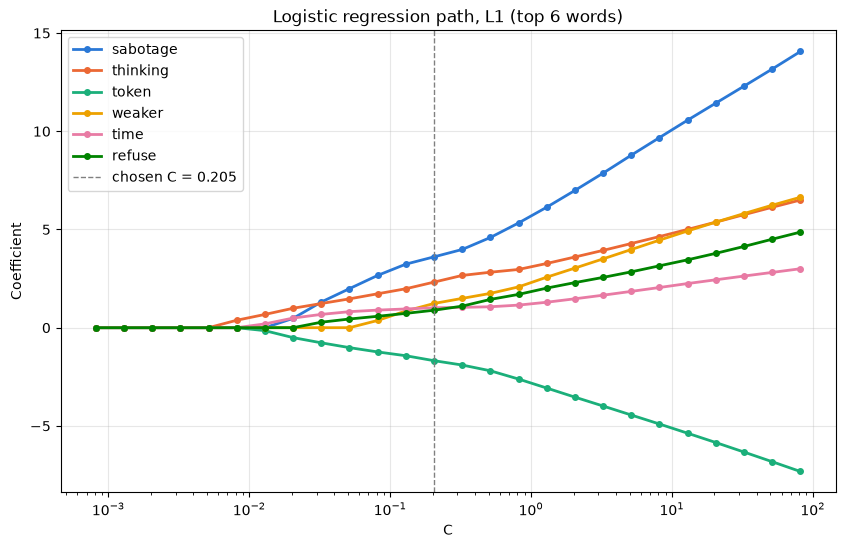

C = 0.2047   training F1 = 0.9211   development F1 = 0.8699


In [79]:
# L1 regularization path, adapted from the scikit-learn example mentioned in homework
# L1 adds lambda * sum(|theta_j|) to the loss so the model ends up using a small subset of words.
import matplotlib.pyplot as plt
from sklearn.svm import l1_min_c

# l1_min_c = the smallest C where the L1 model has at least one non-zero weight after regularization.
# We go from there up to 10^5 times it.
cs = l1_min_c(X_train_bow, y_train, loss="log") * np.logspace(0, 5, 26)

coefs_, f1_dev_path = [], []
for c in cs:
    clf = LogisticRegression(l1_ratio=1, solver="liblinear", C=c, tol=1e-6, max_iter=5000)
    clf.fit(X_train_bow, y_train)
    coefs_.append(clf.coef_.ravel().copy())
    f1_dev_path.append(f1_score(y_dev, clf.predict(X_dev_bow)))
coefs_ = np.array(coefs_)   # shape (number of C values, number of words)

# Pick the C with the highest dev F1
best_idx = int(np.argmax(f1_dev_path))
best_C_l1 = cs[best_idx]

# Plot showing logistic regression path for the 6 words with the largest weight at the chosen C.
vocab = bow_vectorizer.get_feature_names_out()
top_words = np.argsort(-np.abs(coefs_[best_idx]))[:6]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

plt.figure(figsize=(10, 6))
for color, j in zip(colors, top_words):
    plt.semilogx(cs, coefs_[:, j], marker="o", markersize=4, linewidth=2, color=color, label=vocab[j])
plt.axvline(best_C_l1, color="gray", linestyle="--", linewidth=1, label=f"chosen C = {best_C_l1:.3g}")
plt.xlabel("C")
plt.ylabel("Coefficient")
plt.title("Logistic regression path, L1 (top 6 words)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Final L1 model at the chosen C using scikit-learn example.
lr_l1 = LogisticRegression(
    l1_ratio=1, 
    solver="liblinear", 
    C=best_C_l1, 
    tol=1e-6
    )
lr_l1.fit(X_train_bow, y_train)
f1_tr, f1_dv = report("LR, L1", lr_l1, X_train_bow, X_dev_bow)
results["LR L1"] = (f1_tr, f1_dv)
print(f"C = {best_C_l1:.4g}   training F1 = {f1_tr:.4f}   development F1 = {f1_dv:.4f}")

#### (e)(iii) L2 regularization

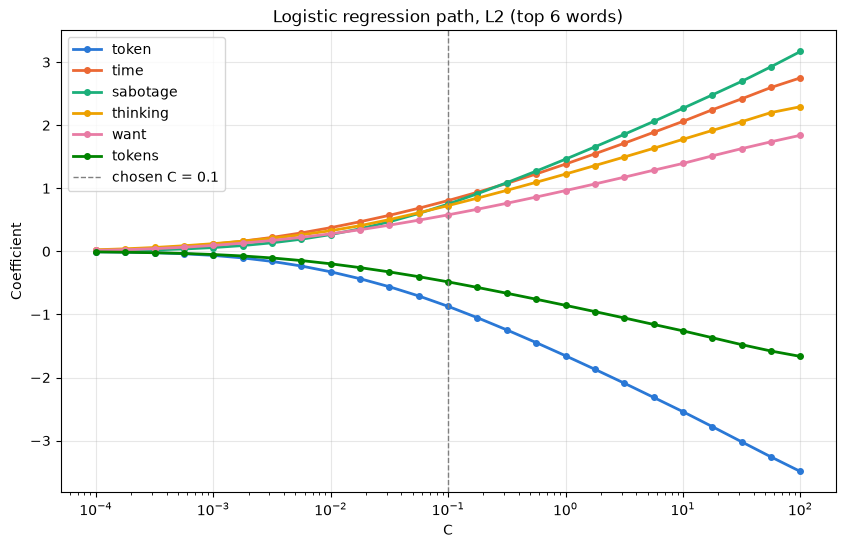

C = 0.1   training F1 = 0.9730   development F1 = 0.8761


In [80]:
# Unlike L1, L2 shrinks weights toward 0 but never makes them exactly 0, so there is no
# "smallest useful C" like l1_min_c. Instead we use a fixed grid of 25 C values from 0.0001 to 100.
cs = np.logspace(-4, 2, 25)

coefs_, f1_dev_path = [], []
for c in cs:
    clf = LogisticRegression(l1_ratio=0, C=c, tol=1e-6, max_iter=5000)   # l1_ratio=0 -> pure L2
    clf.fit(X_train_bow, y_train)
    coefs_.append(clf.coef_.ravel().copy())
    f1_dev_path.append(f1_score(y_dev, clf.predict(X_dev_bow)))
coefs_ = np.array(coefs_)   # shape (number of C values, number of words)

# Pick the C with the highest dev F1
best_idx = int(np.argmax(f1_dev_path))
best_C_l2 = cs[best_idx]

# Plot showing logistic regression path for the 6 words with the largest weight at the chosen C.
vocab = bow_vectorizer.get_feature_names_out()
top_words = np.argsort(-np.abs(coefs_[best_idx]))[:6]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

plt.figure(figsize=(10, 6))
for color, j in zip(colors, top_words):
    plt.semilogx(cs, coefs_[:, j], marker="o", markersize=4, linewidth=2, color=color, label=vocab[j])
plt.axvline(best_C_l2, color="gray", linestyle="--", linewidth=1, label=f"chosen C = {best_C_l2:.3g}")
plt.xlabel("C")
plt.ylabel("Coefficient")
plt.title("Logistic regression path, L2 (top 6 words)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Final L2 model at the chosen C using scikit-learn example.
lr_l2 = LogisticRegression(
    l1_ratio=0, 
    C=best_C_l2, 
    tol=1e-6, 
    max_iter=5000)
lr_l2.fit(X_train_bow, y_train)
f1_tr, f1_dv = report("LR, L2", lr_l2, X_train_bow, X_dev_bow)
results["LR L2"] = (f1_tr, f1_dv)
print(f"C = {best_C_l2:.4g}   training F1 = {f1_tr:.4f}   development F1 = {f1_dv:.4f}")

#### (e)(v) Most important words in the L1 model

In [81]:
# get_feature_names_out() gives the word for each column, in the same order as coef_.
vocab = bow_vectorizer.get_feature_names_out()
weights = lr_l1.coef_[0]          # shape (n_features,), one weight per word

# argsort sorts ascending, so the first entries are the most negative weights
# and the last entries are the most positive weights.
order = np.argsort(weights)
top_flagged = [(vocab[i], round(weights[i], 3)) for i in order[::-1][:15]]
top_normal = [(vocab[i], round(weights[i], 3)) for i in order[:15]]

pd.DataFrame({
    "words pushing toward flagged": top_flagged,
    "words pushing toward normal": top_normal,
})

,words pushing toward flagged,words pushing toward normal
0,"(sabotage, 3.606)","(token, -1.68)"
1,"(thinking, 2.32)","(let, -0.833)"
2,"(weaker, 1.233)","(create, -0.675)"
3,"(time, 1.016)","(gpt, -0.657)"
4,"(refuse, 0.889)","(models, -0.491)"
5,"(want, 0.849)","(with, -0.472)"
6,"(cybersecurity, 0.654)","(prompt, -0.458)"
7,"(masked, 0.58)","(rating, -0.428)"
8,"(im, 0.565)","(print, -0.428)"
9,"(provide, 0.512)","(eof, -0.38)"


### (f) Bernoulli Naive Bayes
Based on textbook implementation

In [82]:
class BernoulliNaiveBayes:
    """Bernoulli Naive Bayes with Laplace smoothing, using only numpy."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha   # Laplace smoothing pseudo-count

    def fit(self, X, y):
        # X: (n_docs, n_words) binary sparse matrix, y: (n_docs,) array of 0/1 labels
        self.classes_ = np.unique(y)                       # array([0, 1])
        n = X.shape[0]
        log_prior, log_psi, log_one_minus_psi = [], [], []
        for k in self.classes_:
            X_k = X[y == k]                                # rows (documents) of class k
            n_k = X_k.shape[0]                             # n_k = number of docs in class k
            # n_jk = number of class-k docs containing word j = column sums of X_k.
            # np.asarray(...).ravel() turns the sparse 1 x d result into a flat numpy array.
            n_jk = np.asarray(X_k.sum(axis=0)).ravel()
            # Laplace smoothing: psi_jk = (n_jk + alpha) / (n_k + 2 * alpha), so it is never 0 or 1.
            psi_k = (n_jk + self.alpha) / (n_k + 2 * self.alpha)
            log_prior.append(np.log(n_k / n))              # log phi_k
            log_psi.append(np.log(psi_k))                  # log P(x_j = 1 | y = k)
            log_one_minus_psi.append(np.log(1 - psi_k))    # log P(x_j = 0 | y = k)
        self.log_prior_ = np.array(log_prior)              # shape (K,)
        log_psi = np.array(log_psi)                        # shape (K, d)
        log_one_minus_psi = np.array(log_one_minus_psi)    # shape (K, d)
        # Pre-compute the two pieces of the linear form:
        #   W[k, j] = log psi_jk - log(1 - psi_jk)  (added when word j IS present)
        #   b[k]    = log phi_k + sum_j log(1 - psi_jk)  (the score of an empty document)
        self.W_ = log_psi - log_one_minus_psi
        self.b_ = self.log_prior_ + log_one_minus_psi.sum(axis=1)
        return self

    def joint_log_likelihood(self, X):
        # log P(x, y=k) for every document and class: (n_docs, d) @ (d, K) + (K,) -> (n_docs, K).
        # X @ W.T works directly on the sparse matrix (no dense conversion needed).
        return np.asarray(X @ self.W_.T) + self.b_

    def predict_proba(self, X):
        # Bayes rule: P(y=k | x) = P(x, y=k) / sum_k' P(x, y=k').
        # Subtract the row max before exponentiating for numerical stability (log-sum-exp trick).
        jll = self.joint_log_likelihood(X)
        jll -= jll.max(axis=1, keepdims=True)
        p = np.exp(jll)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        # Choose the class with the highest posterior (= highest joint log-likelihood).
        return self.classes_[np.argmax(self.joint_log_likelihood(X), axis=1)]

In [83]:
nb_bow = BernoulliNaiveBayes(alpha=1.0).fit(X_train_bow, y_train)
results["Bernoulli NB"] = report("Bernoulli Naive Bayes (alpha=1)", nb_bow, X_train_bow, X_dev_bow)
print(f"Bernoulli Naive Bayes (alpha=1)   development F1 = {results['Bernoulli NB'][1]:.4f}")

Bernoulli Naive Bayes (alpha=1)   development F1 = 0.6913


### (g) Model comparison (generative vs. discriminative)

In [84]:
# All bag-of-words models side by side.
summary = pd.DataFrame(results, index=["training F1", "development F1"]).T
summary["gap (train - dev)"] = summary["training F1"] - summary["development F1"]
summary.round(4)

,training F1,development F1,gap (train - dev)
LR no regularization,1.0000,0.8607,0.1393
LR L1,0.9211,0.8699,0.0511
LR L2,0.9730,0.8761,0.0969
Bernoulli NB,0.7121,0.6913,0.0208


In [85]:
# Illustration of the overconfidence point: how many dev transcripts get a NB posterior that is
# essentially 0 or 1? Counting correlated words over and over pushes probabilities to the extremes.
p_nb = nb_bow.predict_proba(X_dev_bow)[:, 1]
p_lr = lr_l2.predict_proba(X_dev_bow)[:, 1]
print(f"Naive Bayes: {np.mean((p_nb < 1e-3) | (p_nb > 1 - 1e-3)) * 100:.1f}% of dev predictions have P < 0.001 or P > 0.999")
print(f"LogReg (L2): {np.mean((p_lr < 1e-3) | (p_lr > 1 - 1e-3)) * 100:.1f}% of dev predictions have P < 0.001 or P > 0.999")

Naive Bayes: 92.3% of dev predictions have P < 0.001 or P > 0.999
LogReg (L2): 15.2% of dev predictions have P < 0.001 or P > 0.999


### (h) N-gram model (2-grams only)
References d2l Ch. 9.3

In [86]:
# Try several thresholds M and look at vocabulary size and dev F1 (default L2 logistic regression).
# Set ngram_range=(2, 2) to use 2-grams instead of single words.
for M in [2, 5, 10, 20, 50]:
    vec = CountVectorizer(binary=True, ngram_range=(2, 2), min_df=M)
    X_tr = vec.fit_transform(train_text)
    X_dv = vec.transform(dev_text)
    clf = LogisticRegression(max_iter=5000).fit(X_tr, y_train)
    print(f"M = {M:3d}   #2-grams = {X_tr.shape[1]:7d}   dev F1 = {f1_score(y_dev, clf.predict(X_dv)):.4f}")

M =   2   #2-grams =   89076   dev F1 = 0.8683
M =   5   #2-grams =   34809   dev F1 = 0.8827
M =  10   #2-grams =   17808   dev F1 = 0.8803
M =  20   #2-grams =    8511   dev F1 = 0.8766
M =  50   #2-grams =    2977   dev F1 = 0.8601


In [87]:
M_BIGRAM = 10   # chosen threshold

# Same as part (d): fit on train only, then transform both sets.
bigram_vectorizer = CountVectorizer(binary=True, ngram_range=(2, 2), min_df=M_BIGRAM)
X_train_bi = bigram_vectorizer.fit_transform(train_text)
X_dev_bi = bigram_vectorizer.transform(dev_text)

# Print 10 bigrams from the vocabulary. We take a random sample with a fixed seed
bigram_vocab = bigram_vectorizer.get_feature_names_out()
rng = np.random.default_rng(SEED)
print("Ten 2-grams:", list(rng.choice(bigram_vocab, size=10, replace=False)))

Ten 2-grams: ['continue working', 'well reasoned', 'positions with', 'models the', 'variation of', 'with appropriate', 'still correct', 'whether should', 'most recent', 'optimizer max']


In [88]:
# Logistic regression on bigrams. Part (e) showed regularization helps, so we use L2 and
# pick C on the dev set again
C_grid = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]
bi_scores = {}
for C in C_grid:
    clf = LogisticRegression(l1_ratio=0, C=C, max_iter=5000).fit(X_train_bi, y_train)
    bi_scores[C] = f1_score(y_dev, clf.predict(X_dev_bi))
best_C_bi = max(bi_scores, key=bi_scores.get)
print("dev F1 per C:", {C: round(s, 4) for C, s in bi_scores.items()})

lr_bi = LogisticRegression(l1_ratio=0, C=best_C_bi, max_iter=5000).fit(X_train_bi, y_train)
bigram_results = {}
bigram_results["LR L2"] = report(f"2-gram LR, L2, C={best_C_bi}", lr_bi, X_train_bi, X_dev_bi)

# Our own Naive Bayes from part (f), unchanged; it works for any binary feature matrix.
nb_bi = BernoulliNaiveBayes(alpha=1.0).fit(X_train_bi, y_train)
bigram_results["Bernoulli NB"] = report("2-gram Bernoulli NB, alpha=1", nb_bi, X_train_bi, X_dev_bi)

dev F1 per C: {0.01: 0.8426, 0.03: 0.8677, 0.1: 0.8798, 0.3: 0.8803, 1: 0.8803, 3: 0.8766, 10: 0.8837, 100: 0.8866}


In [95]:
# Side-by-side: bag of words vs. 2-grams on the training and development sets.
compare = pd.DataFrame({
    "2-gram hyperparameters": [f"C={best_C_bi:.3g}", "alpha=1"],
    "2-gram training F1": [bigram_results["LR L2"][0], bigram_results["Bernoulli NB"][0]],
    "2-gram dev F1": [bigram_results["LR L2"][1], bigram_results["Bernoulli NB"][1]],
}, index=["Logistic regression (L2)", "Bernoulli Naive Bayes"])
compare.round(4)

,2-gram hyperparameters,2-gram training F1,2-gram dev F1
Logistic regression (L2),C=100,1.0000,0.8866
Bernoulli Naive Bayes,alpha=1,0.6313,0.6179


### (i) Determine performance with the test set 
Although there was not a significant difference between F1 dev scores in 2-gram L2 regression (0.8866) and F1 dev scores in bag-of-words L2 regression (0.8761), I still went with 2-gram L2 regression because it the score was higher.  

In [98]:
# 1) Clean all labeled training text and the test text with the same function as before.
full_text = train_df["text"].map(clean_text)
y_full = train_df["target"].values
test_text = test_df["text"].map(clean_text)

# 2) Re-fit the 2-gram vocabulary on the full training data with the same threshold M,
#    then transform the test data with that same vocabulary.
final_vectorizer = CountVectorizer(binary=True, ngram_range=(2, 2), min_df=M_BIGRAM)
X_full = final_vectorizer.fit_transform(full_text)
X_test = final_vectorizer.transform(test_text)
print("2-grams after re-fitting on all training data:", X_full.shape[1])

# 3) Re-train L2 logistic regression with the C chosen in part (h).
final_model = LogisticRegression(l1_ratio=0, C=best_C_bi, max_iter=5000).fit(X_full, y_full)

# 4) Predict the test set, and only now use the true test labels.
#    Merge on `id` so each prediction is matched to the right label even if row orders differ.
test_pred = pd.DataFrame({"id": test_df["id"], "pred": final_model.predict(X_test)})
scored = test_pred.merge(test_labels_df, on="id")
assert len(scored) == len(test_df)   # every test row got a label

test_f1 = f1_score(scored["target"], scored["pred"])
print(f"Final classifier: 2-grams (min_df={M_BIGRAM}), L2 logistic regression, C={best_C_bi}")
print(f"Test F1: {test_f1:.4f}")

2-grams after re-fitting on all training data: 24330
Final classifier: 2-grams (min_df=10), L2 logistic regression, C=100
Test F1: 0.8903
